# CC3045 - Deep Learning
## Laboratorio 10 - Entrega final

**Autor:** Milton Polanco - 23471

**Semilla aleatoria:** 42

Este notebook contiene los Tasks 1 a 4. Todas las cifras, tablas y conclusiones se calculan en la misma ejecución. Las imágenes se guardan en output/figures/ y los resultados numéricos en output/resultados.json.

**Declaración de herramientas de apoyo.** Se utilizó asistencia de IA para apoyar la escritura de fórmulas.

In [1]:
from pathlib import Path
import copy, json, math, random, time, warnings, importlib.util, subprocess, sys
from urllib.request import urlretrieve
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.special import expit
from scipy.stats import spearmanr

import torch
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms

from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
if importlib.util.find_spec("shap") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
import shap

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

ROOT = Path.cwd()
IMG_DIR = ROOT / "data" / "images"
FIG_DIR = ROOT / "output" / "figures"
IMG_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
image_urls = {
    "a_dog.jpg": "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg",
    "b_cat_dog.jpg": "https://commons.wikimedia.org/wiki/Special:Redirect/file/Cat%20and%20dog%20standoff%20%283926784260%29.jpg",
    "c_dog_cart.jpg": "https://commons.wikimedia.org/wiki/Special:Redirect/file/Shetland%20Sheepdog%20in%20Shopping%20Cart%20at%20Petco.jpg",
}
for filename, url in image_urls.items():
    destination = IMG_DIR / filename
    if not destination.exists():
        urlretrieve(url, destination)
RESULTS = {"semilla": SEED}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)
print("PyTorch:", torch.__version__, "| SHAP:", shap.__version__)

Dispositivo: cuda
PyTorch: 2.13.0+cu130 | SHAP: 0.54.1


## Task 1 - Grad-CAM y CAM sobre ResNet-18

### Task 1.1 - Modelo, preprocesamiento e imágenes

Se usa el redimensionamiento del lado corto a 256, recorte central de 224 por 224 y normalización de ImageNet. Fuentes:

- (a) perro esquimal, imagen de ejemplo del repositorio público *pytorch/hub*: https://github.com/pytorch/hub/blob/master/images/dog.jpg
- (b) perro y gato, Peretz Partensky, CC BY-SA 2.0: https://commons.wikimedia.org/wiki/File:Cat_and_dog_standoff_(3926784260).jpg
- (c) perro dentro de un carrito de compras, Kokostephi, CC0: https://commons.wikimedia.org/wiki/File:Shetland_Sheepdog_in_Shopping_Cart_at_Petco.jpg

La imagen (c) presenta al perro en un contexto atípico dominado visualmente por un carrito rojo. El recuadro del perro, medido después del preprocesamiento geométrico, es $(58, 20, 174, 214)$ en el sistema $(x_{min}, y_{min}, x_{max}, y_{max})$ de la imagen 224 por 224.

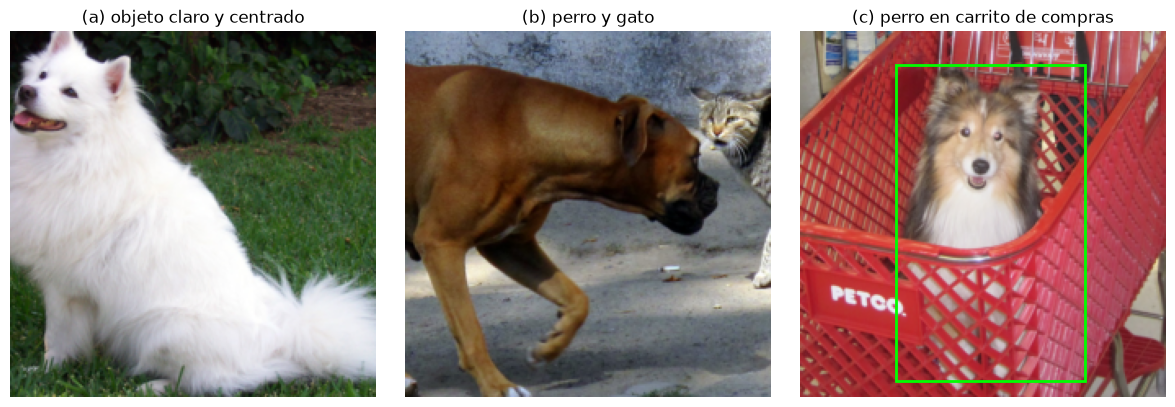

Imagen (a)
  Samoyed                      0.884793
  Arctic fox                   0.045711
  white wolf                   0.044211
  Pomeranian                   0.005623
  Great Pyrenees               0.004655
Imagen (b)
  Rhodesian ridgeback          0.649178
  American Staffordshire terrier 0.106260
  bull mastiff                 0.053913
  Great Dane                   0.051081
  boxer                        0.050373
Imagen (c)
  Shetland sheepdog            0.967136
  collie                       0.027508
  Pomeranian                   0.003798
  shopping basket              0.000333
  Pembroke                     0.000296


In [2]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(DEVICE).eval()
classes = weights.meta["categories"]

resize_crop = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
])
normalize = transforms.Normalize(
    mean=(0.485, 0.456, 0.406),
    std=(0.229, 0.224, 0.225),
)

image_info = {
    "a": {"path": IMG_DIR / "a_dog.jpg", "descripcion": "objeto claro y centrado"},
    "b": {"path": IMG_DIR / "b_cat_dog.jpg", "descripcion": "perro y gato"},
    "c": {"path": IMG_DIR / "c_dog_cart.jpg", "descripcion": "perro en carrito de compras"},
}

display_tensors, input_tensors = {}, {}
for key, info in image_info.items():
    pil = Image.open(info["path"]).convert("RGB")
    cropped = resize_crop(pil)
    display_tensors[key] = transforms.ToTensor()(cropped)
    input_tensors[key] = normalize(display_tensors[key]).unsqueeze(0).to(DEVICE)

bbox_c = (58, 20, 174, 214)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, key in zip(axes, "abc"):
    ax.imshow(display_tensors[key].permute(1, 2, 0))
    ax.set_title(f"({key}) {image_info[key]['descripcion']}")
    ax.axis("off")
    if key == "c":
        x1, y1, x2, y2 = bbox_c
        ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                                   fill=False, color="lime", linewidth=2))
fig.tight_layout()
fig.savefig(FIG_DIR / "task1_imagenes.png", dpi=180, bbox_inches="tight")
plt.show()

top5 = {}
all_logits = {}
with torch.no_grad():
    for key in "abc":
        logits = model(input_tensors[key])
        probs = logits.softmax(1)[0]
        vals, idxs = probs.topk(5)
        top5[key] = [
            {"clase": classes[i], "indice": int(i), "probabilidad": float(v)}
            for v, i in zip(vals.cpu(), idxs.cpu())
        ]
        all_logits[key] = logits.detach()
        print(f"Imagen ({key})")
        for row in top5[key]:
            print(f"  {row['clase']:<28s} {row['probabilidad']:.6f}")
RESULTS["task1_1"] = {"top5": top5, "bbox_c": bbox_c}

### Task 1.2 - Grad-CAM desde cero

El hook de avance conserva las activaciones de *layer4* y el hook de retroceso conserva el gradiente del **logit** de la clase respecto de esas activaciones. Para cada canal se calcula

\[
\alpha_k^c=\frac{1}{49}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}},
\qquad
L^c=\operatorname{ReLU}\left(\sum_k\alpha_k^c A^k\right).
\]

El mapa se interpola bilinealmente a 224 por 224 y luego se normaliza entre su mínimo y máximo.

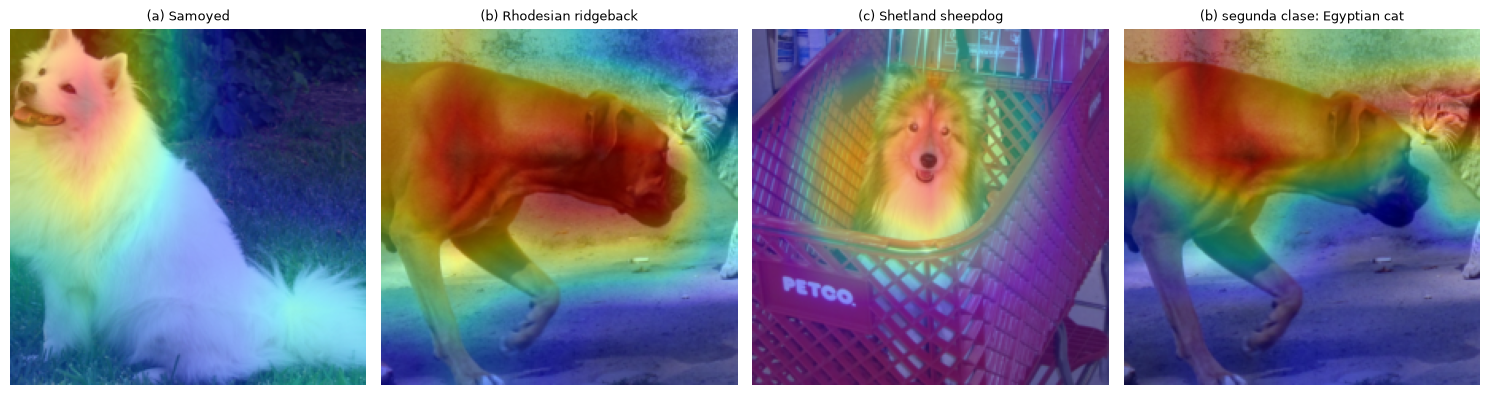

In [3]:
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.hf = layer.register_forward_hook(self._forward_hook)
        self.hb = layer.register_full_backward_hook(self._backward_hook)

    def _forward_hook(self, module, inputs, output):
        self.activations = output.detach()

    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def compute(self, x, class_idx):
        self.model.zero_grad(set_to_none=True)
        logits = self.model(x)
        logits[0, class_idx].backward()
        alpha = self.gradients.mean(dim=(2, 3), keepdim=True)
        raw = (alpha * self.activations).sum(dim=1, keepdim=True)
        relu = F.relu(raw)
        up = F.interpolate(relu, size=(224, 224), mode="bilinear", align_corners=False)
        mn, mx = up.amin((2, 3), keepdim=True), up.amax((2, 3), keepdim=True)
        norm = (up - mn) / (mx - mn + 1e-12)
        return {
            "logits": logits.detach(), "alpha": alpha.detach(),
            "raw7": raw.detach(), "relu7": relu.detach(),
            "map224": norm.detach(), "activations": self.activations.detach(),
            "gradients": self.gradients.detach(),
        }

    def close(self):
        self.hf.remove(); self.hb.remove()

gradcam = GradCAM(model, model.layer4)
primary_class = {k: top5[k][0]["indice"] for k in "abc"}

# Para la segunda clase semántica de (b), se elige la clase felina con mayor logit.
cat_names = ["tabby", "tiger cat", "Persian cat", "Siamese cat", "Egyptian cat"]
cat_indices = [classes.index(name) for name in cat_names]
with torch.no_grad():
    logits_b = model(input_tensors["b"])[0]
second_b = max(cat_indices, key=lambda i: float(logits_b[i]))

gc = {k: gradcam.compute(input_tensors[k], primary_class[k]) for k in "abc"}
gc_b_second = gradcam.compute(input_tensors["b"], second_b)

def overlay(ax, image_tensor, heatmap, title):
    image = image_tensor.permute(1, 2, 0).cpu().numpy()
    ax.imshow(image)
    ax.imshow(heatmap, cmap="jet", alpha=0.42, vmin=0, vmax=1)
    ax.set_title(title, fontsize=9)
    ax.axis("off")

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, key in zip(axes[:3], "abc"):
    overlay(ax, display_tensors[key], gc[key]["map224"][0,0].cpu().numpy(),
            f"({key}) {classes[primary_class[key]]}")
overlay(axes[3], display_tensors["b"], gc_b_second["map224"][0,0].cpu().numpy(),
        f"(b) segunda clase: {classes[second_b]}")
fig.tight_layout()
fig.savefig(FIG_DIR / "task1_gradcam.png", dpi=180, bbox_inches="tight")
plt.show()

RESULTS["task1_2"] = {
    "clases_principales": {k: classes[v] for k, v in primary_class.items()},
    "segunda_clase_b": classes[second_b],
}

### Task 1.3 - CAM y relación numérica con Grad-CAM

Como ResNet-18 aplica promedio global antes de *fc*, el mapa sin gradientes es

\[
M^c_{ij}=\sum_k w_k^c A^k_{ij}.
\]

Se comprueban la descomposición del logit, la identidad $49 \times GradCAM_{sin\ ReLU} = CAM$ y la igualdad de ambos mapas después de ReLU y normalización.

In [4]:
def minmax7(x):
    y = F.relu(x)
    return (y - y.min()) / (y.max() - y.min() + 1e-12)

cam_checks = {}
cam_maps = {}
for key in "abc":
    c = primary_class[key]
    A = gc[key]["activations"][0]
    w = model.fc.weight[c].detach()
    M = (w[:, None, None] * A).sum(0)
    logit_from_cam = float(M.mean() + model.fc.bias[c].detach())
    logit_model = float(gc[key]["logits"][0, c])
    error_logit = abs(logit_from_cam - logit_model)
    error_raw = float((49 * gc[key]["raw7"][0,0] - M).abs().max())
    error_norm = float((minmax7(49 * gc[key]["raw7"][0,0]) - minmax7(M)).abs().max())
    cam_checks[key] = {
        "clase": classes[c], "logit_modelo": logit_model,
        "logit_descompuesto": logit_from_cam,
        "error_logit": error_logit,
        "error_max_sin_relu": error_raw,
        "error_max_normalizado": error_norm,
    }
    cam_maps[key] = M.detach()

cam_table = pd.DataFrame(cam_checks).T
print(cam_table.to_string())
RESULTS["task1_3"] = cam_checks

                 clase logit_modelo logit_descompuesto error_logit error_max_sin_relu error_max_normalizado
a              Samoyed    16.273741          16.273743    0.000002           0.000008                   0.0
b  Rhodesian ridgeback    14.713373          14.713374    0.000001           0.000004                   0.0
c    Shetland sheepdog    17.980591          17.980591         0.0           0.000008                   0.0


### Task 1.4 - Análisis cuantitativo

 canal    alpha     w/49  error_relativo
    31 0.007019 0.007019    0.000000e+00
    83 0.005233 0.005233    0.000000e+00
   314 0.005148 0.005148    9.045501e-08
   454 0.004576 0.004576    0.000000e+00
   378 0.004413 0.004413    1.055116e-07


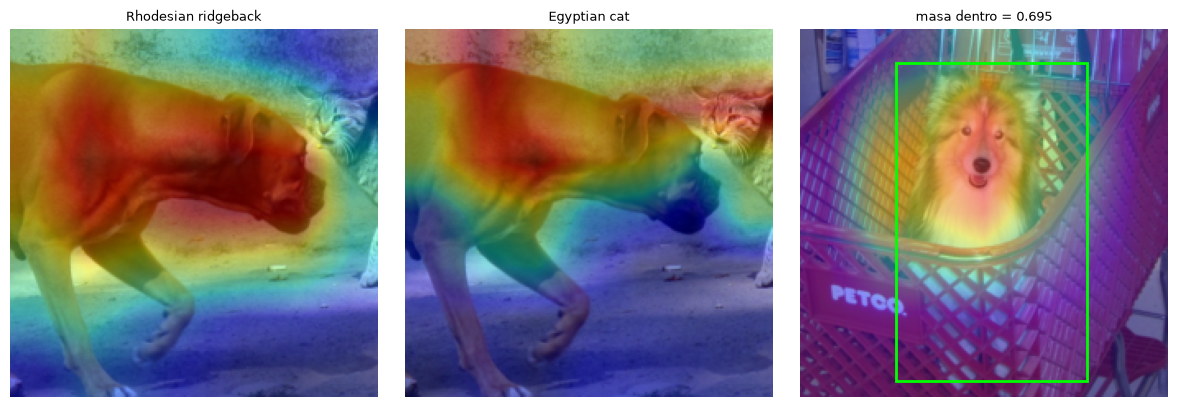

IoU del 20% superior en (b): 0.224668
Masa de Grad-CAM dentro del recuadro de (c): 0.695482
Probabilidad original: 0.967136
Probabilidad con fondo gris: 0.819089
Cambio (gris - original): -0.148047


In [5]:
# (a) Comparación alpha_k^c contra w_k^c / Z para los cinco pesos de mayor magnitud.
c_a = primary_class["a"]
w_a = model.fc.weight[c_a].detach()
alpha_a = gc["a"]["alpha"][0, :, 0, 0]
top_channels = torch.topk(w_a.abs(), 5).indices
rows_alpha = []
for ch in top_channels:
    ch = int(ch)
    expected = float(w_a[ch] / 49)
    observed = float(alpha_a[ch])
    rel = abs(observed - expected) / (abs(expected) + 1e-15)
    rows_alpha.append({"canal": ch, "alpha": observed, "w/49": expected, "error_relativo": rel})
alpha_table = pd.DataFrame(rows_alpha)
print(alpha_table.to_string(index=False))

# (b) IoU de los píxeles del 20% superior de los dos mapas de (b).
map_b1 = gc["b"]["map224"][0,0].cpu().numpy()
map_b2 = gc_b_second["map224"][0,0].cpu().numpy()
q1, q2 = np.quantile(map_b1, 0.8), np.quantile(map_b2, 0.8)
set1, set2 = map_b1 >= q1, map_b2 >= q2
iou_b = float(np.logical_and(set1, set2).sum() / np.logical_or(set1, set2).sum())

# (c) Masa dentro del recuadro y prueba causal reemplazando el exterior por gris medio.
x1, y1, x2, y2 = bbox_c
map_c = gc["c"]["map224"][0,0].cpu().numpy()
mass_inside = float(map_c[y1:y2, x1:x2].sum() / map_c.sum())
gray_outside = display_tensors["c"].clone()
mask = torch.zeros((224,224), dtype=torch.bool)
mask[y1:y2, x1:x2] = True
gray_outside[:, ~mask] = 0.5
x_gray = normalize(gray_outside).unsqueeze(0).to(DEVICE)
with torch.no_grad():
    p_original = float(model(input_tensors["c"]).softmax(1)[0, primary_class["c"]])
    p_gray = float(model(x_gray).softmax(1)[0, primary_class["c"]])
prob_change = p_gray - p_original

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
overlay(axes[0], display_tensors["b"], map_b1, classes[primary_class["b"]])
overlay(axes[1], display_tensors["b"], map_b2, classes[second_b])
overlay(axes[2], display_tensors["c"], map_c, f"masa dentro = {mass_inside:.3f}")
axes[2].add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, color="lime", linewidth=2))
fig.tight_layout()
fig.savefig(FIG_DIR / "task1_analisis.png", dpi=180, bbox_inches="tight")
plt.show()

print(f"IoU del 20% superior en (b): {iou_b:.6f}")
print(f"Masa de Grad-CAM dentro del recuadro de (c): {mass_inside:.6f}")
print(f"Probabilidad original: {p_original:.6f}")
print(f"Probabilidad con fondo gris: {p_gray:.6f}")
print(f"Cambio (gris - original): {prob_change:+.6f}")

RESULTS["task1_4"] = {
    "comparacion_alpha": rows_alpha,
    "iou_top20_b": iou_b,
    "masa_dentro_bbox_c": mass_inside,
    "prob_original_c": p_original,
    "prob_fondo_gris_c": p_gray,
    "cambio_probabilidad_c": prob_change,
}

**Interpretación del Task 1.4.** La igualdad espacial del gradiente aparece al derivar el promedio global: cada activación entra al descriptor con el mismo factor $1/Z$, por lo que $\partial y^c/\partial A^k_{ij} = w_k^c/Z$ para toda posición $(i,j)$. Los errores residuales no son cero exacto porque la suma, el promedio y la retropropagación se evalúan con aritmética *float32*, cuyo redondeo depende del orden de las operaciones.

El IoU cuantifica si los mapas de las dos clases separan regiones distintas. Un IoU bajo apoya discriminación espacial; uno alto revela que ambos logits usan evidencia compartida. En cualquier caso, las 49 celdas de *layer4* tienen paso efectivo de 32 píxeles: objetos pequeños o muy cercanos pueden caer en la misma celda y no se pueden localizar con precisión fina.

En (c), la masa dentro del recuadro se contrasta con una intervención: conservar solo el objeto y neutralizar el fondo. Si la masa se concentra en el recuadro y la probabilidad cambia poco, ambas pruebas coinciden en que el fondo no es decisivo. Si el mapa asigna masa afuera y la probabilidad cae al neutralizar el exterior, hay evidencia de un atajo contextual. Una discrepancia recuerda que Grad-CAM es asociativo y de baja resolución, mientras que la intervención modifica causalmente la entrada.

## Task 2 - Explicaciones para riesgo de crédito

### Task 2.1 - German Credit y modelo base

Las categorías se codifican ordinalmente ajustando el codificador solo con entrenamiento. Estos números no representan distancias semánticas; el modelo puede introducir divisiones arbitrarias entre códigos, limitación que debe tenerse presente al interpretar SHAP.

In [6]:
datos = fetch_openml("credit-g", version=1, as_frame=True)
X_raw = datos.data.copy()
y = (datos.target.astype(str) == "good").astype(int)

cat_cols = X_raw.select_dtypes(include=["category", "object"]).columns.tolist()
num_cols = [c for c in X_raw.columns if c not in cat_cols]

idx_train, idx_test = train_test_split(
    np.arange(len(X_raw)), test_size=0.20, stratify=y, random_state=SEED
)
X_train_raw = X_raw.iloc[idx_train].copy()
X_test_raw = X_raw.iloc[idx_test].copy()
y_train = y.iloc[idx_train].to_numpy()
y_test = y.iloc[idx_test].to_numpy()

encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
encoder.fit(X_train_raw[cat_cols])

def encode_frame(frame):
    out = frame.copy()
    out[cat_cols] = encoder.transform(frame[cat_cols])
    return out.astype(float)

X_train_df = encode_frame(X_train_raw)
X_test_df = encode_frame(X_test_raw)
feature_names = X_train_df.columns.tolist()

credit_model = GradientBoostingClassifier(
    n_estimators=200, max_depth=3, random_state=SEED
)
credit_model.fit(X_train_df, y_train)
pred = credit_model.predict(X_test_df)
prob = credit_model.predict_proba(X_test_df)[:, 1]
accuracy = accuracy_score(y_test, pred)
auc = roc_auc_score(y_test, prob)
print("Numéricas:", len(num_cols), num_cols)
print("Categóricas:", len(cat_cols), cat_cols)
print(f"Exactitud: {accuracy:.6f}")
print(f"AUC:       {auc:.6f}")
RESULTS["task2_1"] = {"exactitud": float(accuracy), "auc": float(auc),
                        "numericas": num_cols, "categoricas": cat_cols}

Numéricas: 7 ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categóricas: 13 ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']
Exactitud: 0.775000
AUC:       0.765000


### Task 2.2 - TreeSHAP intervencional

La salida explicada es el log-odds (*decision_function*). El fondo contiene 100 instancias de entrenamiento elegidas sin reemplazo con la semilla reportada.

Error máximo de eficiencia: 9.722e-08
Valor base SHAP: 1.430742147
Media log-odds del fondo: 1.430742147

Top 5 SHAP:
 checking_status    0.760287
purpose            0.511731
credit_amount      0.490213
duration           0.391748
savings_status     0.296328
dtype: float64

Top 5 permutación:
 checking_status    0.119000
credit_amount      0.076250
duration           0.057905
credit_history     0.039643
savings_status     0.026155
dtype: float64

Spearman de rankings completos: 0.649624


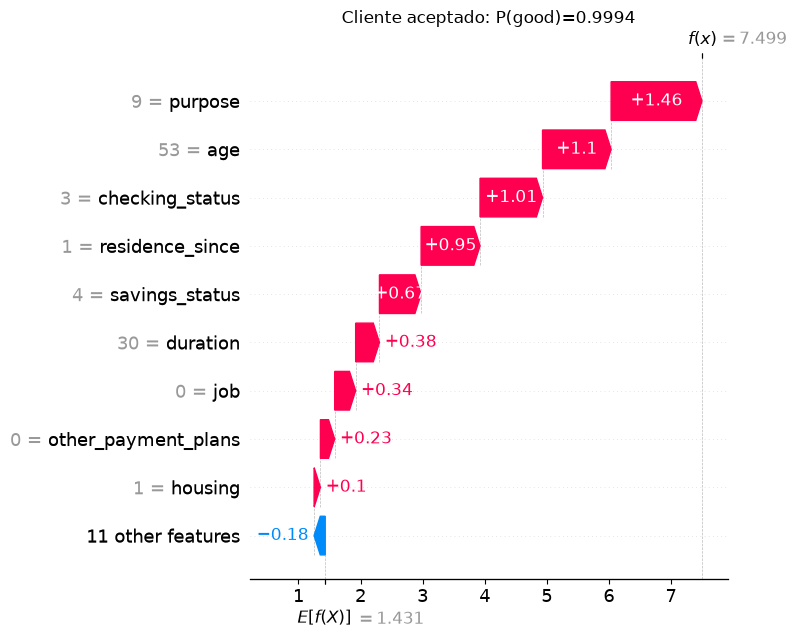

aceptado [{'variable': 'purpose', 'phi': 1.4632943248574157, 'valor': 9.0}, {'variable': 'age', 'phi': 1.104481383948587, 'valor': 53.0}, {'variable': 'checking_status', 'phi': 1.0068690238008275, 'valor': 3.0}]


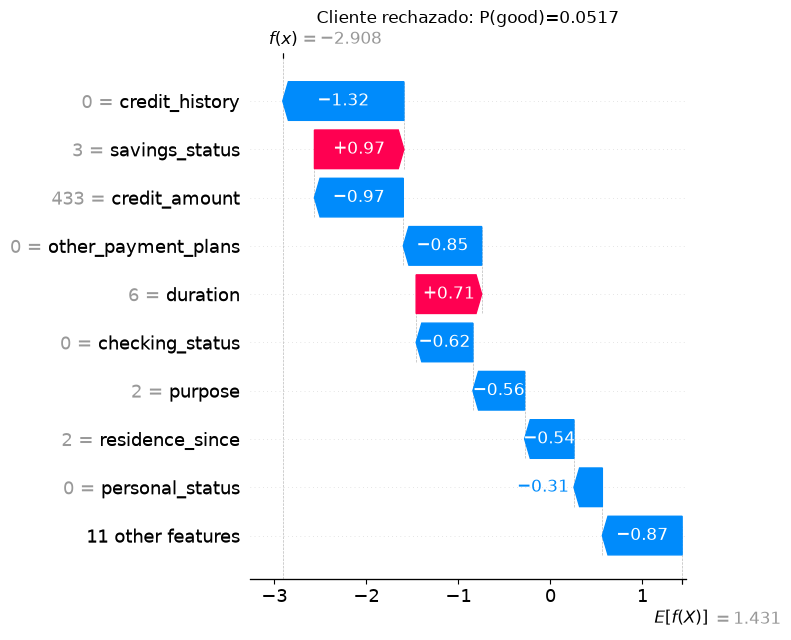

rechazado [{'variable': 'credit_history', 'phi': -1.316188054861268, 'valor': 0.0}, {'variable': 'savings_status', 'phi': 0.9721066182595678, 'valor': 3.0}, {'variable': 'credit_amount', 'phi': -0.9653949067025678, 'valor': 433.0}]


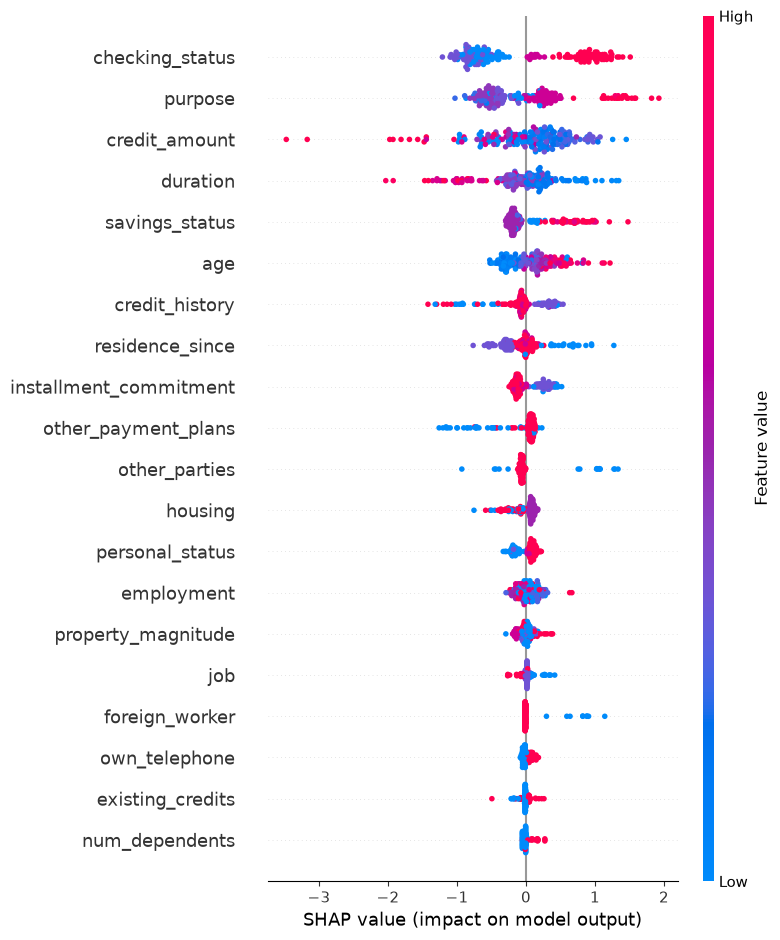

In [7]:
rng = np.random.default_rng(SEED)
bg_idx_100 = rng.choice(len(X_train_df), size=100, replace=False)
background100 = X_train_df.iloc[bg_idx_100]

tree_explainer = shap.TreeExplainer(
    credit_model, data=background100,
    feature_perturbation="interventional", model_output="raw"
)
shap_values = np.asarray(tree_explainer.shap_values(X_test_df))
base_value = float(np.asarray(tree_explainer.expected_value).reshape(-1)[0])
raw_output = credit_model.decision_function(X_test_df)
eff_errors = np.abs(base_value + shap_values.sum(1) - raw_output)
max_eff_error = float(eff_errors.max())
background_mean_raw = float(credit_model.decision_function(background100).mean())

global_shap = np.abs(shap_values).mean(0)
perm = permutation_importance(
    credit_model, X_test_df, y_test, scoring="roc_auc",
    n_repeats=10, random_state=SEED, n_jobs=-1
)
rank_shap = pd.Series(global_shap, index=feature_names).rank(ascending=False, method="average")
rank_perm = pd.Series(perm.importances_mean, index=feature_names).rank(ascending=False, method="average")
rho_rank = float(spearmanr(rank_shap, rank_perm).statistic)

top_shap = pd.Series(global_shap, index=feature_names).sort_values(ascending=False).head(5)
top_perm = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False).head(5)
print(f"Error máximo de eficiencia: {max_eff_error:.3e}")
print(f"Valor base SHAP: {base_value:.9f}")
print(f"Media log-odds del fondo: {background_mean_raw:.9f}")
print("\nTop 5 SHAP:\n", top_shap)
print("\nTop 5 permutación:\n", top_perm)
print(f"\nSpearman de rankings completos: {rho_rank:.6f}")

# Se eligen los casos más extremo entre quienes cumplen los umbrales.
accepted_idx = int(np.where(prob > 0.8)[0][np.argmax(prob[prob > 0.8])])
rejected_idx = int(np.where(prob < 0.2)[0][np.argmin(prob[prob < 0.2])])

def top_contributions(i, n=3):
    order = np.argsort(np.abs(shap_values[i]))[::-1][:n]
    return [{"variable": feature_names[j], "phi": float(shap_values[i,j]),
             "valor": float(X_test_df.iloc[i,j])} for j in order]

for label, i in [("aceptado", accepted_idx), ("rechazado", rejected_idx)]:
    ex = shap.Explanation(values=shap_values[i], base_values=base_value,
                          data=X_test_df.iloc[i].to_numpy(), feature_names=feature_names)
    shap.plots.waterfall(ex, max_display=10, show=False)
    plt.title(f"Cliente {label}: P(good)={prob[i]:.4f}")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"task2_waterfall_{label}.png", dpi=180, bbox_inches="tight")
    plt.show()
    print(label, top_contributions(i))

shap_exp = shap.Explanation(
    values=shap_values, base_values=np.full(len(X_test_df), base_value),
    data=X_test_df.to_numpy(), feature_names=feature_names
)
shap.plots.beeswarm(shap_exp, max_display=20, show=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "task2_beeswarm.png", dpi=180, bbox_inches="tight")
plt.show()

RESULTS["task2_2"] = {
    "error_max_eficiencia": max_eff_error,
    "valor_base": base_value, "media_fondo_logodds": background_mean_raw,
    "top5_shap": {k: float(v) for k,v in top_shap.items()},
    "top5_permutacion": {k: float(v) for k,v in top_perm.items()},
    "spearman_rankings": rho_rank,
    "cliente_aceptado": {"posicion_test": accepted_idx, "probabilidad": float(prob[accepted_idx]),
                           "top3": top_contributions(accepted_idx)},
    "cliente_rechazado": {"posicion_test": rejected_idx, "probabilidad": float(prob[rejected_idx]),
                            "top3": top_contributions(rejected_idx)},
}

### Task 2.3 - Variable redundante

Se duplica la variable numérica de mayor importancia SHAP global y se agrega ruido gaussiano con desviación $0.05\,\sigma_x$. La importancia conjunta se reporta como el promedio de $|\phi_{original} + \phi_{copia}|$.

In [8]:
numeric_importance = pd.Series({c: global_shap[feature_names.index(c)] for c in num_cols})
dup_var = numeric_importance.idxmax()
dup_name = dup_var + "_copia"
sigma_x = float(X_train_df[dup_var].std(ddof=0))
rng_dup = np.random.default_rng(SEED)

X_train_dup = X_train_df.copy()
X_test_dup = X_test_df.copy()
X_train_dup[dup_name] = X_train_dup[dup_var] + 0.05 * sigma_x * rng_dup.standard_normal(len(X_train_dup))
X_test_dup[dup_name] = X_test_dup[dup_var] + 0.05 * sigma_x * rng_dup.standard_normal(len(X_test_dup))

model_dup = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED)
model_dup.fit(X_train_dup, y_train)
bg_dup = X_train_dup.iloc[bg_idx_100]

expl_inter_dup = shap.TreeExplainer(model_dup, data=bg_dup,
    feature_perturbation="interventional", model_output="raw")
sv_inter_dup = np.asarray(expl_inter_dup.shap_values(X_test_dup))
expl_path_dup = shap.TreeExplainer(model_dup,
    feature_perturbation="tree_path_dependent", model_output="raw")
sv_path_dup = np.asarray(expl_path_dup.shap_values(X_test_dup))

i_orig = X_train_dup.columns.get_loc(dup_var)
i_copy = X_train_dup.columns.get_loc(dup_name)
dup_rows = []
for name, values in [("interventional", sv_inter_dup), ("tree_path_dependent", sv_path_dup)]:
    dup_rows.append({
        "configuracion": name,
        "mean_abs_original": float(np.abs(values[:, i_orig]).mean()),
        "mean_abs_copia": float(np.abs(values[:, i_copy]).mean()),
        "mean_abs_suma": float(np.abs(values[:, i_orig] + values[:, i_copy]).mean()),
    })
dup_table = pd.DataFrame(dup_rows)
base_original_importance = float(global_shap[feature_names.index(dup_var)])
print(dup_table.to_string(index=False))
print("Variable duplicada:", dup_var)
print("Importancia original sin copia:", base_original_importance)
RESULTS["task2_3"] = {"variable": dup_var, "sigma": sigma_x,
                        "importancia_sin_copia": base_original_importance,
                        "tabla": dup_rows}

      configuracion  mean_abs_original  mean_abs_copia  mean_abs_suma
     interventional           0.508211        0.183287       0.517805
tree_path_dependent           0.426735        0.202834       0.494598
Variable duplicada: credit_amount
Importancia original sin copia: 0.4902134791654752


### Task 2.4 - KernelSHAP frente a TreeSHAP

Se explican las mismas 10 instancias y, para cada tamaño de fondo, TreeSHAP usa exactamente ese fondo como referencia. El error es la media de $|\phi_{Kernel} - \phi_{Tree}|$ sobre instancias y variables.

In [9]:
X10 = X_test_df.iloc[:10]
kernel_rows = []
kernel_values_by_bg = {}
for bg_size in (10, 50, 100):
    local_rng = np.random.default_rng(SEED + bg_size)
    ids = local_rng.choice(len(X_train_df), size=bg_size, replace=False)
    bg = X_train_df.iloc[ids]
    tree_same = shap.TreeExplainer(credit_model, data=bg,
        feature_perturbation="interventional", model_output="raw")
    sv_tree_same = np.asarray(tree_same.shap_values(X10))

    kernel = shap.KernelExplainer(credit_model.decision_function, bg)
    t0 = time.perf_counter()
    sv_kernel = np.asarray(kernel.shap_values(X10, nsamples=2000, silent=True))
    elapsed = time.perf_counter() - t0
    mae = float(np.abs(sv_kernel - sv_tree_same).mean())
    kernel_rows.append({"fondo": bg_size, "MAE_vs_TreeSHAP": mae,
                        "tiempo_s": float(elapsed), "tiempo_por_instancia_s": float(elapsed/10)})
    kernel_values_by_bg[bg_size] = sv_kernel
    print(kernel_rows[-1])
kernel_table = pd.DataFrame(kernel_rows)
print(kernel_table.to_string(index=False))
RESULTS["task2_4"] = kernel_rows

{'fondo': 10, 'MAE_vs_TreeSHAP': 0.045059278325202075, 'tiempo_s': 1.2172106999787502, 'tiempo_por_instancia_s': 0.12172106999787502}


{'fondo': 50, 'MAE_vs_TreeSHAP': 0.030570880740923165, 'tiempo_s': 4.233816299994942, 'tiempo_por_instancia_s': 0.4233816299994942}


{'fondo': 100, 'MAE_vs_TreeSHAP': 0.032233832553648825, 'tiempo_s': 7.6768200999940746, 'tiempo_por_instancia_s': 0.7676820099994075}
 fondo  MAE_vs_TreeSHAP  tiempo_s  tiempo_por_instancia_s
    10         0.045059  1.217211                0.121721
    50         0.030571  4.233816                0.423382
   100         0.032234  7.676820                0.767682


### Task 2.5 - Fórmula exacta de Shapley con seis variables

Para cada subconjunto $S$, $v(S)$ es el promedio del log-odds sobre las 50 filas del fondo después de sustituir por el cliente las columnas presentes en $S$. Se enumeran las 64 coaliciones y se aplica el peso $|S|!(M-|S|-1)!/M!$ sin utilizar *shap* en este cálculo.

In [10]:
warnings.filterwarnings("ignore", category=UserWarning)
six_features = ["duration", "credit_amount", "installment_commitment",
                "residence_since", "age", "existing_credits"]
X6_train = X_train_df[six_features]
X6_test = X_test_df[six_features]
model6 = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED)
model6.fit(X6_train, y_train)
rng6 = np.random.default_rng(SEED)
bg6 = X6_train.iloc[rng6.choice(len(X6_train), size=50, replace=False)].to_numpy()

def coalition_value(model, x, background, mask):
    mixed = background.copy()
    cols = np.flatnonzero(mask)
    if len(cols):
        mixed[:, cols] = x[cols]
    return float(model.decision_function(mixed).mean())

def exact_shapley(model, x, background):
    m = len(x)
    values = {}
    for bits in range(1 << m):
        mask = np.array([(bits >> j) & 1 for j in range(m)], dtype=bool)
        values[bits] = coalition_value(model, x, background, mask)
    phi = np.zeros(m)
    for j in range(m):
        for bits in range(1 << m):
            if (bits >> j) & 1:
                continue
            s = bits.bit_count()
            weight = math.factorial(s) * math.factorial(m-s-1) / math.factorial(m)
            phi[j] += weight * (values[bits | (1 << j)] - values[bits])
    return phi, values

exact_rows = []
exact_values = []
for i in range(5):
    phi, vals = exact_shapley(model6, X6_test.iloc[i].to_numpy(), bg6)
    exact_values.append(phi)
    eff = abs(phi.sum() - (vals[(1 << 6)-1] - vals[0]))
    exact_rows.append({"instancia": i, "error_eficiencia": float(eff)})
exact_values = np.vstack(exact_values)

tree6 = shap.TreeExplainer(model6, data=bg6,
    feature_perturbation="interventional", model_output="raw")
sv_tree6 = np.asarray(tree6.shap_values(X6_test.iloc[:5]))
max_error_exact = float(np.abs(exact_values - sv_tree6).max())
max_eff_exact = float(max(r["error_eficiencia"] for r in exact_rows))
print("Error máximo contra TreeSHAP:", f"{max_error_exact:.3e}")
print("Error máximo de eficiencia propia:", f"{max_eff_exact:.3e}")
print(pd.DataFrame(exact_rows).to_string(index=False))
RESULTS["task2_5"] = {"features": six_features,
                        "error_max_vs_treeshap": max_error_exact,
                        "error_max_eficiencia": max_eff_exact,
                        "por_instancia": exact_rows}

Error máximo contra TreeSHAP: 2.431e-08
Error máximo de eficiencia propia: 5.551e-16
 instancia  error_eficiencia
         0      8.326673e-17
         1      2.220446e-16
         2      5.551115e-16
         3      0.000000e+00
         4      1.387779e-16


### Task 2.6 - Análisis de confiabilidad e interpretación

In [11]:
# (a) No aditividad al transformar log-odds a probabilidad.
i = rejected_idx
p_x = float(prob[i])
p_base = float(expit(base_value))
individual_effects = expit(base_value + shap_values[i]) - p_base
sum_prob_effects = float(individual_effects.sum())
actual_prob_effect = float(p_x - p_base)

# (b) Mayor discrepancia de posición y correlaciones.
rank_gap = (rank_shap - rank_perm).abs().sort_values(ascending=False)
gap_feature = rank_gap.index[0]
correlations = X_train_df.corr(method="spearman")[gap_feature].drop(gap_feature)
top_correlations = correlations.reindex(correlations.abs().sort_values(ascending=False).index).head(5)

# (d) Medición estable de predicción sobre lotes de 100.
batch100 = X_test_df.iloc[:100]
loops = 200
t0 = time.perf_counter()
for _ in range(loops):
    credit_model.predict_proba(batch100)
pred100_time = (time.perf_counter() - t0) / loops
exact20_seconds = pred100_time * (2**20)
exact20_hours = exact20_seconds / 3600
exact60_years = (2**60 * 1e-6) / (365.25 * 24 * 3600)

print(f"Cliente rechazado: p(x)={p_x:.6f}, p_base={p_base:.6f}")
print(f"Suma de efectos individuales en probabilidad: {sum_prob_effects:+.6f}")
print(f"Cambio real de probabilidad: {actual_prob_effect:+.6f}")
print(f"Mayor discrepancia de ranking: {gap_feature} (brecha {rank_gap.iloc[0]:.1f})")
print("Correlaciones Spearman más altas:\n", top_correlations)
print(f"Predicción de 100 instancias: {pred100_time:.6f} s")
print(f"Estimación exacta, 20 variables: {exact20_seconds:.1f} s = {exact20_hours:.3f} h")
print(f"Cálculo exacto, 60 variables a 1 us/evaluación: {exact60_years:,.1f} años")

RESULTS["task2_6"] = {
    "rechazado_prob": p_x, "prob_base": p_base,
    "suma_efectos_individuales_prob": sum_prob_effects,
    "cambio_real_prob": actual_prob_effect,
    "variable_mayor_brecha_ranking": gap_feature,
    "brecha_ranking": float(rank_gap.iloc[0]),
    "top_correlaciones": {k: float(v) for k,v in top_correlations.items()},
    "tiempo_prediccion_100_s": float(pred100_time),
    "estimacion_exacta_20_s": float(exact20_seconds),
    "estimacion_exacta_20_h": float(exact20_hours),
    "exacta_60_anios_1us": float(exact60_years),
}

Cliente rechazado: p(x)=0.051742, p_base=0.807017
Suma de efectos individuales en probabilidad: -0.945725
Cambio real de probabilidad: -0.755275
Mayor discrepancia de ranking: age (brecha 14.0)
Correlaciones Spearman más altas:
 housing           -0.312011
employment         0.306383
personal_status    0.272981
residence_since    0.244567
credit_history    -0.199944
Name: age, dtype: float64
Predicción de 100 instancias: 0.001880 s
Estimación exacta, 20 variables: 1971.2 s = 0.548 h
Cálculo exacto, 60 variables a 1 us/evaluación: 36,533.9 años


**Interpretación del Task 2.6.**

**(a)** SHAP es aditivo en la escala explicada: $\phi_0 + \sum_j \phi_j = f(x)$ para el log-odds. La sigmoide no es lineal, por lo que en general $\sum_j[\sigma(\phi_0+\phi_j)-\sigma(\phi_0)]$ no coincide con $\sigma(\phi_0+\sum_j\phi_j)-\sigma(\phi_0)$. La diferencia observada es el efecto de curvatura e interacción introducido por el cambio de escala.

**(b)** La permutación mide cuánto cae el AUC cuando se destruye la información de una variable en prueba; SHAP mide el tamaño medio de su contribución al log-odds bajo un fondo específico. Una variable correlacionada puede recibir contribuciones SHAP grandes y, aun así, causar poca caída al permutarla porque otras variables conservan información sustitutiva. Las correlaciones impresas permiten evaluar esta hipótesis para la mayor discrepancia.

**(c)** La simetría de Shapley repartiría el crédito por igual si la variable y su copia fueran jugadores exactamente intercambiables para la función de valor. Aquí no lo son: la copia contiene ruido y el entrenamiento basado en árboles puede escoger umbrales distintos. La versión intervencional rompe dependencias usando el fondo; *tree_path_dependent* usa conteos de entrenamiento en las rutas de los árboles y solo aproxima una expectativa condicional. Por eso un valor SHAP describe la atribución del modelo bajo supuestos concretos, no una importancia causal en el mundo real.

**(d)** Para 2,000 muestras por instancia, el costo dominante esperado de KernelSHAP es aproximadamente proporcional al tamaño del fondo porque cada coalición debe evaluarse contra sus filas. Los tiempos medidos comprueban esa tendencia; el error no tiene obligación de decrecer monótonamente con el tamaño del fondo porque también intervienen el muestreo de coaliciones y el cambio de la distribución de referencia. La comparación con $2^{20}$ y $2^{60}$ muestra por qué la enumeración exacta deja de ser viable.

## Task 3 - LIME y explicaciones contrafactuales

### Task 3.1 - LIME tabular desde cero

La representación interpretable tiene una variable binaria por atributo original. Una variable presente conserva el valor del cliente y una ausente toma un valor aleatorio de la columna de entrenamiento. Para $D^2$ variables ausentes, el peso local es

\[
\pi_x(z)=\exp\left(-\frac{D^2}{\sigma^2}\right),
\qquad \sigma=0.75\sqrt{20}.
\]

La regresión ridge ponderada se resuelve en forma cerrada. El intercepto no se penaliza; primero se ajustan las 20 variables, se seleccionan las $K=5$ de mayor coeficiente absoluto y se vuelve a ajustar solo con ellas.

   cliente  prob_good               variable  coeficiente  R2_ponderado
  aceptado   0.999447                purpose     0.104621      0.252305
  aceptado   0.999447        residence_since     0.073880      0.252305
  aceptado   0.999447        checking_status     0.063783      0.252305
  aceptado   0.999447         savings_status     0.059433      0.252305
  aceptado   0.999447                    age     0.060432      0.252305
 rechazado   0.051742         credit_history    -0.205765      0.307008
 rechazado   0.051742         savings_status     0.152097      0.307008
 rechazado   0.051742          credit_amount    -0.143613      0.307008
 rechazado   0.051742               duration     0.118523      0.307008
 rechazado   0.051742    other_payment_plans    -0.109558      0.307008
intermedio   0.503997        checking_status     0.248554      0.302651
intermedio   0.503997               duration    -0.170684      0.302651
intermedio   0.503997          credit_amount    -0.096531      0

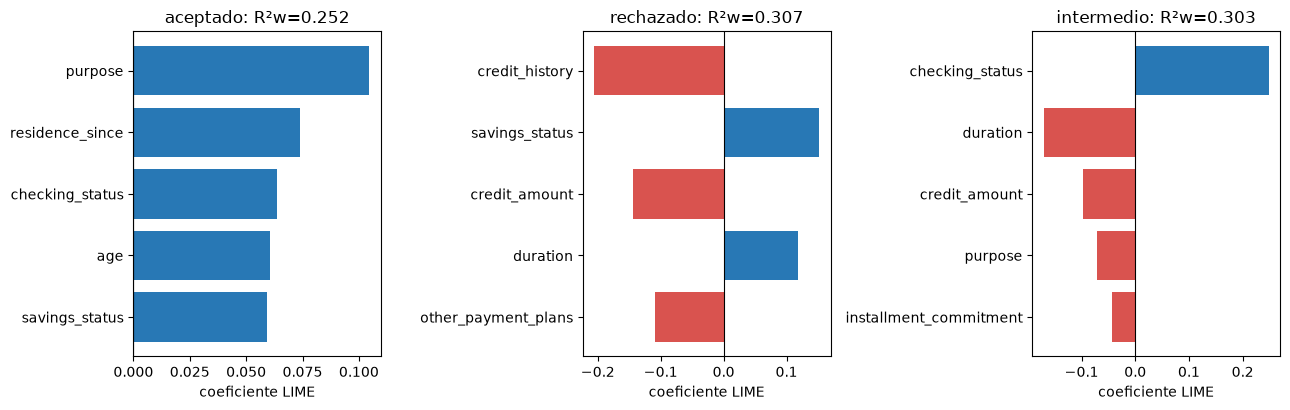

In [12]:
X_train_np = X_train_df.to_numpy(dtype=float)
d_lime = X_train_np.shape[1]

def weighted_ridge(z, y_local, weights, lam=1.0):
    design = np.column_stack([np.ones(len(z)), z])
    penalty = np.eye(design.shape[1]) * lam
    penalty[0, 0] = 0.0  # El intercepto no se penaliza.
    gram = design.T @ (weights[:, None] * design) + penalty
    rhs = design.T @ (weights * y_local)
    return np.linalg.solve(gram, rhs)

def lime_tabular(x, n_samples=5000, k=5, sigma_rel=0.75, seed=SEED):
    rng_local = np.random.default_rng(seed)
    z = rng_local.binomial(1, 0.5, size=(n_samples, d_lime)).astype(float)
    sampled_rows = rng_local.integers(0, len(X_train_np), size=(n_samples, d_lime))
    sampled = X_train_np[sampled_rows, np.arange(d_lime)[None, :]]
    perturbed = np.where(z.astype(bool), np.asarray(x)[None, :], sampled)
    y_local = credit_model.predict_proba(
        pd.DataFrame(perturbed, columns=feature_names)
    )[:, 1]

    d_squared = d_lime - z.sum(axis=1)
    sigma = sigma_rel * np.sqrt(d_lime)
    weights_local = np.exp(-d_squared / (sigma ** 2))

    full_beta = weighted_ridge(z, y_local, weights_local, lam=1.0)
    selected = np.argsort(np.abs(full_beta[1:]))[::-1][:k]
    selected_beta = weighted_ridge(z[:, selected], y_local, weights_local, lam=1.0)
    fitted = selected_beta[0] + z[:, selected] @ selected_beta[1:]
    weighted_mean = np.sum(weights_local * y_local) / np.sum(weights_local)
    numerator = np.sum(weights_local * (y_local - fitted) ** 2)
    denominator = np.sum(weights_local * (y_local - weighted_mean) ** 2)
    r2_weighted = 1.0 - numerator / denominator
    n_effective = weights_local.sum() ** 2 / np.square(weights_local).sum()
    return {
        "full_intercept": float(full_beta[0]),
        "full_coef": full_beta[1:],
        "selected": selected,
        "selected_intercept": float(selected_beta[0]),
        "selected_coef": selected_beta[1:],
        "r2": float(r2_weighted),
        "n_effective": float(n_effective),
    }

middle_candidates = np.where((prob >= 0.45) & (prob <= 0.55))[0]
if len(middle_candidates):
    middle_idx = int(middle_candidates[np.argmin(np.abs(prob[middle_candidates] - 0.5))])
else:
    middle_idx = int(np.argmin(np.abs(prob - 0.5)))

lime_clients = {
    "aceptado": accepted_idx,
    "rechazado": rejected_idx,
    "intermedio": middle_idx,
}
lime_results = {}
lime_rows = []
for offset, (label, idx_client) in enumerate(lime_clients.items()):
    result = lime_tabular(
        X_test_df.iloc[idx_client].to_numpy(), n_samples=5000, k=5,
        sigma_rel=0.75, seed=SEED + 300 + offset
    )
    lime_results[label] = result
    for feature_idx, coef in zip(result["selected"], result["selected_coef"]):
        lime_rows.append({
            "cliente": label,
            "prob_good": float(prob[idx_client]),
            "variable": feature_names[int(feature_idx)],
            "coeficiente": float(coef),
            "R2_ponderado": result["r2"],
        })

lime_table = pd.DataFrame(lime_rows)
print(lime_table.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (label, result) in zip(axes, lime_results.items()):
    names = [feature_names[int(j)] for j in result["selected"]]
    values = np.asarray(result["selected_coef"])
    colors_bar = np.where(values >= 0, "#2878B5", "#D9534F")
    order = np.argsort(np.abs(values))
    ax.barh(np.asarray(names)[order], values[order], color=colors_bar[order])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{label}: R²w={result['r2']:.3f}")
    ax.set_xlabel("coeficiente LIME")
fig.tight_layout()
fig.savefig(FIG_DIR / "task3_lime_clientes.png", dpi=180, bbox_inches="tight")
plt.show()

RESULTS["task3_1"] = {
    "clientes": {
        label: {
            "posicion_test": int(lime_clients[label]),
            "probabilidad": float(prob[lime_clients[label]]),
            "r2_ponderado": float(result["r2"]),
            "coeficientes": {
                feature_names[int(j)]: float(v)
                for j, v in zip(result["selected"], result["selected_coef"])
            },
        }
        for label, result in lime_results.items()
    },
    "intercepto_penalizado": False,
}

### Task 3.2 - Estabilidad de LIME

Para cada combinación se ejecuta LIME 20 veces con semillas distintas. La estabilidad se mide con el Jaccard medio entre todos los pares de conjuntos de cinco variables. El tamaño efectivo es

\[
N_{ef}=\frac{\left(\sum_n \pi_n\right)^2}{\sum_n \pi_n^2}.
\]

Jaccard promedio
sigma_rel      0.50      0.75      1.50
N                                      
500        0.734336  0.762907  0.750627
2000       0.966667  0.966667  0.966667
5000       1.000000  1.000000  1.000000

Tamaño efectivo promedio
sigma_rel         0.50         0.75         1.50
N                                               
500         407.947807   480.671928   498.755362
2000       1640.603484  1924.000881  1995.050846
5000       4097.267765  4806.802247  4987.650805


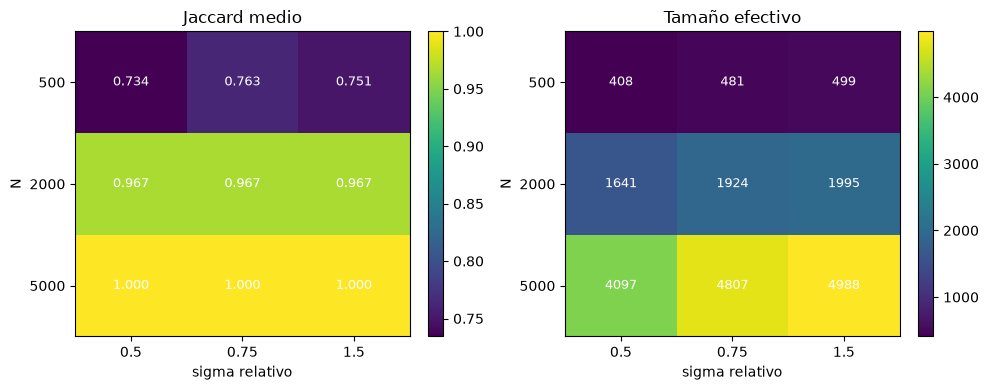

In [13]:
stability_rows = []
rejected_x = X_test_df.iloc[rejected_idx].to_numpy()
for n_samples in (500, 2000, 5000):
    for sigma_rel in (0.5, 0.75, 1.5):
        selected_sets, effective_sizes = [], []
        for run in range(20):
            result = lime_tabular(
                rejected_x, n_samples=n_samples, k=5, sigma_rel=sigma_rel,
                seed=SEED + 100000 + n_samples * 10 + int(100 * sigma_rel) + run
            )
            selected_sets.append(set(map(int, result["selected"])))
            effective_sizes.append(result["n_effective"])
        jaccards = [
            len(selected_sets[a] & selected_sets[b]) / len(selected_sets[a] | selected_sets[b])
            for a, b in combinations(range(20), 2)
        ]
        stability_rows.append({
            "N": n_samples,
            "sigma_rel": sigma_rel,
            "Jaccard_promedio": float(np.mean(jaccards)),
            "N_ef_promedio": float(np.mean(effective_sizes)),
        })

stability_table = pd.DataFrame(stability_rows)
print("Jaccard promedio")
print(stability_table.pivot(index="N", columns="sigma_rel", values="Jaccard_promedio").to_string())
print("\nTamaño efectivo promedio")
print(stability_table.pivot(index="N", columns="sigma_rel", values="N_ef_promedio").to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, value, title, fmt_value in [
    (axes[0], "Jaccard_promedio", "Jaccard medio", ".3f"),
    (axes[1], "N_ef_promedio", "Tamaño efectivo", ".0f"),
]:
    pivot = stability_table.pivot(index="N", columns="sigma_rel", values=value)
    im = ax.imshow(pivot.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(pivot.columns)), [str(x) for x in pivot.columns])
    ax.set_yticks(range(len(pivot.index)), [str(x) for x in pivot.index])
    ax.set_xlabel("sigma relativo")
    ax.set_ylabel("N")
    ax.set_title(title)
    for row_i in range(len(pivot.index)):
        for col_i in range(len(pivot.columns)):
            ax.text(col_i, row_i, format(pivot.iloc[row_i, col_i], fmt_value),
                    ha="center", va="center", color="white", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIG_DIR / "task3_lime_estabilidad.png", dpi=180, bbox_inches="tight")
plt.show()

RESULTS["task3_2"] = stability_rows

### Task 3.3 - Comparación entre LIME y SHAP

La comparación usa los coeficientes absolutos del primer ajuste LIME con 20 variables y los valores SHAP absolutos de la misma instancia. Para el cliente rechazado también se evalúa la fidelidad al variar $K$.

In [14]:
comparison_rows = []
for label, idx_client in lime_clients.items():
    abs_lime = np.abs(lime_results[label]["full_coef"])
    abs_shap = np.abs(shap_values[idx_client])
    rho = float(spearmanr(abs_lime, abs_shap).statistic)
    top_lime = set(np.argsort(abs_lime)[::-1][:3])
    top_shap_local = set(np.argsort(abs_shap)[::-1][:3])
    overlap = sorted(feature_names[j] for j in top_lime & top_shap_local)
    comparison_rows.append({
        "cliente": label,
        "Spearman_abs": rho,
        "coincidencias_top3": len(overlap),
        "variables_comunes": ", ".join(overlap) if overlap else "ninguna",
    })

k_rows = []
for k_value in (3, 5, 10, 20):
    result = lime_tabular(
        rejected_x, n_samples=5000, k=k_value, sigma_rel=0.75,
        seed=SEED + 303
    )
    k_rows.append({"K": k_value, "R2_ponderado": float(result["r2"])})

print(pd.DataFrame(comparison_rows).to_string(index=False))
print("\nFidelidad del cliente rechazado según K")
print(pd.DataFrame(k_rows).to_string(index=False))
RESULTS["task3_3"] = {"comparacion": comparison_rows, "fidelidad_por_K": k_rows}

   cliente  Spearman_abs  coincidencias_top3                             variables_comunes
  aceptado      0.816541                   2                      checking_status, purpose
 rechazado      0.926316                   3 credit_amount, credit_history, savings_status
intermedio      0.917293                   3      checking_status, credit_amount, duration

Fidelidad del cliente rechazado según K
 K  R2_ponderado
 3      0.216393
 5      0.306307
10      0.364406
20      0.371855


### Task 3.4 - Explicaciones contrafactuales

Se generan 20,000 candidatos que modifican entre una y tres variables accionables. Las variables inmutables son *age*, *personal_status* y *foreign_worker*. La distancia suma cambios categóricos y cambios numéricos normalizados por la desviación absoluta mediana.

In [15]:
immutable_features = {"age", "personal_status", "foreign_worker"}
actionable = ["duration", "credit_amount", "installment_commitment",
              "checking_status", "savings_status"]
actionable_num = {"duration", "credit_amount", "installment_commitment"}
actionable_cat = set(actionable) - actionable_num
original_cf = X_test_df.iloc[rejected_idx].copy()

def numeric_scale(name):
    values = X_train_df[name].to_numpy()
    median = np.median(values)
    mad = np.median(np.abs(values - median))
    if mad == 0:
        mad = np.mean(np.abs(values - values.mean()))
    return float(mad if mad > 0 else 1.0)

mad_values = {name: numeric_scale(name) for name in actionable_num}

def generate_counterfactuals(max_changes=3, n_candidates=20000, seed=SEED + 3400):
    rng_cf = np.random.default_rng(seed)
    candidates = np.repeat(original_cf.to_numpy()[None, :], n_candidates, axis=0)
    changed_sets = []
    for row in range(n_candidates):
        amount = int(rng_cf.integers(1, max_changes + 1))
        chosen = rng_cf.choice(actionable, size=amount, replace=False).tolist()
        actual = []
        for name in chosen:
            col_idx = feature_names.index(name)
            possibilities = np.unique(X_train_df[name].to_numpy())
            alternatives = possibilities[possibilities != original_cf[name]]
            pool = alternatives if len(alternatives) else possibilities
            new_value = float(rng_cf.choice(pool))
            candidates[row, col_idx] = new_value
            if new_value != original_cf[name]:
                actual.append(name)
        changed_sets.append(frozenset(actual))

    candidate_df = pd.DataFrame(candidates, columns=feature_names)
    candidate_prob = credit_model.predict_proba(candidate_df)[:, 1]
    distances = np.zeros(n_candidates)
    for name in actionable_num:
        distances += np.abs(candidate_df[name].to_numpy() - original_cf[name]) / mad_values[name]
    for name in actionable_cat:
        distances += (candidate_df[name].to_numpy() != original_cf[name]).astype(float)
    return candidate_df, candidate_prob, distances, changed_sets

cf_candidates, cf_prob, cf_distance, cf_sets = generate_counterfactuals(max_changes=3)
valid_idx = np.flatnonzero(cf_prob >= 0.5)
max_changes_used = 3
if len(valid_idx) == 0:
    cf_candidates, cf_prob, cf_distance, cf_sets = generate_counterfactuals(
        max_changes=5, seed=SEED + 3401
    )
    valid_idx = np.flatnonzero(cf_prob >= 0.5)
    max_changes_used = 5

ordered_valid = valid_idx[np.argsort(cf_distance[valid_idx])]
selected_cf = []
used_sets = set()
for idx_candidate in ordered_valid:
    change_set = cf_sets[int(idx_candidate)]
    if change_set and change_set not in used_sets:
        selected_cf.append(int(idx_candidate))
        used_sets.add(change_set)
    if len(selected_cf) == 3:
        break

def decode_feature_value(name, value):
    if name not in cat_cols:
        return f"{float(value):g}"
    category_values = encoder.categories_[cat_cols.index(name)]
    code_value = int(round(float(value)))
    if 0 <= code_value < len(category_values):
        return str(category_values[code_value])
    return str(value)

cf_rows = []
for number, idx_candidate in enumerate(selected_cf, start=1):
    changes = []
    for name in actionable:
        old, new = original_cf[name], cf_candidates.iloc[idx_candidate][name]
        if old != new:
            changes.append({
                "variable": name,
                "original": decode_feature_value(name, old),
                "nuevo": decode_feature_value(name, new),
            })
    cf_rows.append({
        "contrafactual": number,
        "cambios": changes,
        "distancia": float(cf_distance[idx_candidate]),
        "prob_good": float(cf_prob[idx_candidate]),
        "variables_cambiadas": len(changes),
    })

validity = float(len(valid_idx) / len(cf_prob))
mean_proximity = float(cf_distance[valid_idx].mean())
mean_sparsity = float(np.mean([len(cf_sets[int(j)]) for j in valid_idx]))
for row in cf_rows:
    formatted = "; ".join(
        f"{x['variable']}: {x['original']} -> {x['nuevo']}" for x in row["cambios"]
    )
    print(f"CF {row['contrafactual']}: {formatted}; distancia={row['distancia']:.3f}; "
          f"P(good)={row['prob_good']:.3f}")
print(f"Validez: {validity:.4f}")
print(f"Proximidad promedio entre válidos: {mean_proximity:.3f}")
print(f"Variables cambiadas promedio entre válidos: {mean_sparsity:.3f}")

RESULTS["task3_4"] = {
    "max_cambios_usado": max_changes_used,
    "validez": validity,
    "proximidad_promedio": mean_proximity,
    "dispersion_promedio": mean_sparsity,
    "seleccionados": cf_rows,
}

CF 1: credit_amount: 433 -> 454; checking_status: 0<=X<200 -> no checking; distancia=1.020; P(good)=0.596
CF 2: duration: 6 -> 7; credit_amount: 433 -> 458; checking_status: 0<=X<200 -> no checking; distancia=1.190; P(good)=0.596
CF 3: credit_amount: 433 -> 426; installment_commitment: 4 -> 2; distancia=2.007; P(good)=0.585
Validez: 0.0062
Proximidad promedio entre válidos: 4.047
Variables cambiadas promedio entre válidos: 2.789


### Task 3.5 - Análisis de estabilidad, discrepancias y utilidad

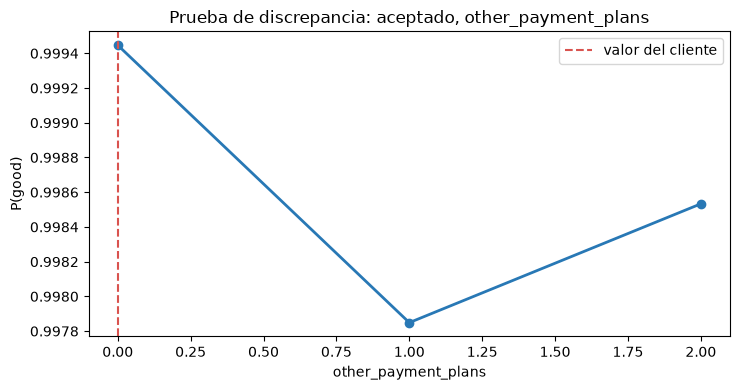

Estimación para Jaccard 0.9: N=1500; verificación Jaccard=0.907, N_ef=1441.1
Mayor discrepancia: cliente=aceptado, variable=other_payment_plans, brecha=12.0, ranking LIME=20.0, ranking SHAP=8.0
Con sigma_rel=0.5, ranking LIME de other_payment_plans: 12.0
K elegido=20, R2 ponderado=0.372
Top 3 SHAP rechazado=['credit_history', 'savings_status', 'credit_amount']; variables en CF=['checking_status', 'credit_amount', 'duration', 'installment_commitment']
Variable SHAP alta ausente=credit_history; phi=-1.3162; razón=no accionable en la búsqueda


In [16]:
# (a) Extrapolación lineal de J respecto de 1/sqrt(N_ef).
stable_075 = stability_table[stability_table["sigma_rel"] == 0.75].sort_values("N")
x_stability = 1 / np.sqrt(stable_075["N_ef_promedio"].to_numpy())
y_stability = stable_075["Jaccard_promedio"].to_numpy()
slope_stability, intercept_stability = np.polyfit(x_stability, y_stability, 1)
target_x = (0.90 - intercept_stability) / slope_stability
target_neff = 1 / max(target_x, 1e-9) ** 2
n_to_neff = float(np.median(stable_075["N"] / stable_075["N_ef_promedio"]))
estimated_n = int(np.clip(math.ceil(target_neff * n_to_neff / 500) * 500, 500, 50000))
if estimated_n in {500, 2000, 5000}:
    estimated_n += 500

verification_sets, verification_neff = [], []
for run in range(20):
    result = lime_tabular(
        rejected_x, n_samples=estimated_n, k=5, sigma_rel=0.75,
        seed=SEED + 350000 + run
    )
    verification_sets.append(set(map(int, result["selected"])))
    verification_neff.append(result["n_effective"])
verification_jaccards = [
    len(verification_sets[a] & verification_sets[b]) /
    len(verification_sets[a] | verification_sets[b])
    for a, b in combinations(range(20), 2)
]
verified_jaccard = float(np.mean(verification_jaccards))
verified_neff = float(np.mean(verification_neff))

# (b) Mayor brecha de ranking entre LIME y SHAP para los tres clientes.
discrepancies = []
for label, idx_client in lime_clients.items():
    lime_rank = pd.Series(np.abs(lime_results[label]["full_coef"]), index=feature_names).rank(
        ascending=False, method="average"
    )
    shap_rank = pd.Series(np.abs(shap_values[idx_client]), index=feature_names).rank(
        ascending=False, method="average"
    )
    gaps = (lime_rank - shap_rank).abs()
    for name, gap in gaps.items():
        discrepancies.append((float(gap), label, int(idx_client), name,
                              float(lime_rank[name]), float(shap_rank[name])))
largest_gap, gap_client, gap_idx, gap_variable, rank_lime_gap, rank_shap_gap = max(discrepancies)

lime_narrow = lime_tabular(
    X_test_df.iloc[gap_idx].to_numpy(), n_samples=5000, k=5,
    sigma_rel=0.5, seed=SEED + 3600
)
narrow_rank = pd.Series(np.abs(lime_narrow["full_coef"]), index=feature_names).rank(
    ascending=False, method="average"
)

if gap_variable in cat_cols:
    curve_values = np.sort(X_train_df[gap_variable].unique())
else:
    curve_values = np.unique(np.quantile(X_train_df[gap_variable], np.linspace(0.02, 0.98, 60)))
curve_frame = pd.DataFrame(
    np.repeat(X_test_df.iloc[gap_idx].to_numpy()[None, :], len(curve_values), axis=0),
    columns=feature_names,
)
curve_frame[gap_variable] = curve_values
curve_prob = credit_model.predict_proba(curve_frame)[:, 1]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(curve_values, curve_prob, marker="o" if len(curve_values) <= 15 else None,
        color="#2878B5", linewidth=2)
ax.axvline(X_test_df.iloc[gap_idx][gap_variable], color="#D9534F", linestyle="--",
           label="valor del cliente")
ax.set_xlabel(gap_variable)
ax.set_ylabel("P(good)")
ax.set_title(f"Prueba de discrepancia: {gap_client}, {gap_variable}")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "task3_discrepancia.png", dpi=180, bbox_inches="tight")
plt.show()

# (c) Se elige el menor K que alcanza R2 ponderado de 0.80; si ninguno llega, el de mayor fidelidad.
k_frame = pd.DataFrame(k_rows)
eligible_k = k_frame[k_frame["R2_ponderado"] >= 0.80]
chosen_k = int(eligible_k.iloc[0]["K"] if len(eligible_k) else
               k_frame.loc[k_frame["R2_ponderado"].idxmax(), "K"])
chosen_r2 = float(k_frame.loc[k_frame["K"] == chosen_k, "R2_ponderado"].iloc[0])

# (d) Comparación de las variables contrafactuales con las contribuciones SHAP principales.
changed_union = {change["variable"] for row in cf_rows for change in row["cambios"]}
shap_order_rejected = np.argsort(np.abs(shap_values[rejected_idx]))[::-1]
top3_rejected = [feature_names[int(j)] for j in shap_order_rejected[:3]]
missing_high = next((name for name in top3_rejected if name not in changed_union),
                    feature_names[int(next(j for j in shap_order_rejected
                                           if feature_names[int(j)] not in changed_union))])
missing_idx = feature_names.index(missing_high)
if missing_high in immutable_features:
    missing_reason = "inmutable"
elif missing_high not in actionable:
    missing_reason = "no accionable en la búsqueda"
elif missing_high in actionable_num:
    missing_reason = f"cambio penalizado por MAD={mad_values[missing_high]:.3f}"
else:
    missing_reason = "cambio categórico con costo unitario"

print(f"Estimación para Jaccard 0.9: N={estimated_n}; verificación Jaccard={verified_jaccard:.3f}, "
      f"N_ef={verified_neff:.1f}")
print(f"Mayor discrepancia: cliente={gap_client}, variable={gap_variable}, "
      f"brecha={largest_gap:.1f}, ranking LIME={rank_lime_gap:.1f}, ranking SHAP={rank_shap_gap:.1f}")
print(f"Con sigma_rel=0.5, ranking LIME de {gap_variable}: {narrow_rank[gap_variable]:.1f}")
print(f"K elegido={chosen_k}, R2 ponderado={chosen_r2:.3f}")
print(f"Top 3 SHAP rechazado={top3_rejected}; variables en CF={sorted(changed_union)}")
print(f"Variable SHAP alta ausente={missing_high}; phi={shap_values[rejected_idx, missing_idx]:+.4f}; "
      f"razón={missing_reason}")

RESULTS["task3_5"] = {
    "estimacion_N_jaccard_09": estimated_n,
    "verificacion_jaccard": verified_jaccard,
    "verificacion_N_ef": verified_neff,
    "mayor_discrepancia": {
        "cliente": gap_client, "variable": gap_variable, "brecha_ranking": largest_gap,
        "rank_lime_sigma_075": rank_lime_gap, "rank_shap": rank_shap_gap,
        "rank_lime_sigma_05": float(narrow_rank[gap_variable]),
    },
    "K_elegido": chosen_k, "R2_elegido": chosen_r2,
    "umbral_R2_propuesto": 0.80,
    "top3_shap_rechazado": top3_rejected,
    "variables_contrafactuales": sorted(changed_union),
    "variable_shap_alta_ausente": missing_high,
    "phi_variable_ausente": float(shap_values[rejected_idx, missing_idx]),
    "razon_ausencia": missing_reason,
}

**Interpretación del Task 3.5.**

**(a)** La estabilidad mejora cuando crece el tamaño efectivo. La extrapolación usa la relación empírica $1-J\propto 1/\sqrt{N_{ef}}$ y se contrasta con veinte corridas adicionales en el tamaño estimado; por eso la verificación no depende de una sola semilla.

**(b)** Una brecha de ranking puede deberse a que SHAP reparte contribuciones sobre el fondo completo mientras LIME ajusta una aproximación local sobre perturbaciones binarias. El cambio de ancho del kernel y la curva univariada permiten distinguir localidad de no linealidad; si la brecha persiste con un vecindario más estrecho y la curva cambia por tramos, la explicación más plausible es no linealidad o interacción.

**(c)** Para una decisión de crédito se propone una fidelidad ponderada mínima de 0.80. Se prefiere el menor $K$ que la alcance para conservar comprensibilidad. Si ningún ajuste llega al umbral, no se presenta LIME como explicación suficiente: se amplía el modelo local, se revisa el vecindario o se entrega una técnica con validación más fuerte.

**(d)** SHAP responde qué variables contribuyeron a la predicción observada bajo una referencia; el contrafactual responde qué cambios permitidos habrían cruzado el umbral con poca distancia. Una variable de gran contribución puede no aparecer si es inmutable, no accionable o demasiado costosa.

## Task 4 - Validación de explicaciones

### Task 4.1 - Deletion e insertion para Grad-CAM

Cada curva usa 20 pasos. En *deletion* se reemplazan primero los píxeles más importantes por gris medio; en *insertion* se parte de una imagen desenfocada con $σ=10$ y se restituyen esos píxeles. La referencia aleatoria usa diez órdenes por imagen. Un mapa es mejor que el azar cuando su AUC de *deletion* es menor y su AUC de *insertion* es mayor.

imagen  AUC_del_mapa  AUC_del_azar_media  AUC_del_azar_sd  mejora_del      z_del  AUC_ins_mapa  AUC_ins_azar_media  AUC_ins_azar_sd  mejora_ins      z_ins
     a      0.047093            0.171852         0.026134    0.124759   4.773785      0.592406            0.198860         0.016548    0.393546  23.782278
     b      0.046283            0.005920         0.002193   -0.040363 -18.407218      0.619802            0.089603         0.013583    0.530199  39.033827
     c      0.000011            0.010009         0.007997    0.009998   1.250220      0.859371            0.094434         0.007480    0.764937 102.261805


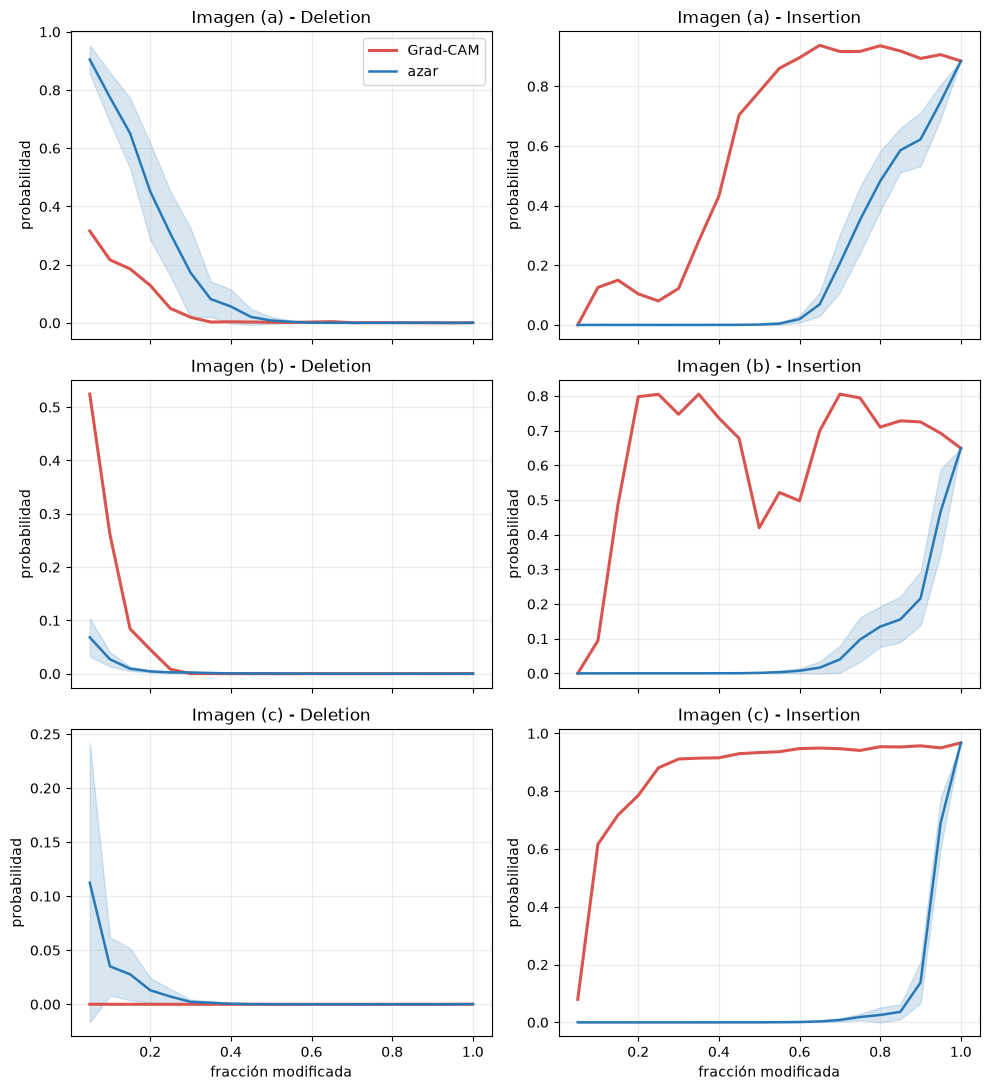

In [17]:
P_STEPS = 20
mean_tensor = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std_tensor = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def predict_display_batch(batch, class_idx, eval_model=model):
    normalized = (batch - mean_tensor) / std_tensor
    with torch.no_grad():
        return eval_model(normalized.to(DEVICE)).softmax(1)[:, class_idx].cpu().numpy()

def perturbation_curve(image, order, class_idx, mode, baseline):
    total_pixels = image.shape[1] * image.shape[2]
    current = image.clone() if mode == "deletion" else baseline.clone()
    source = baseline if mode == "deletion" else image
    current_flat = current.reshape(3, -1)
    source_flat = source.reshape(3, -1)
    frames = []
    previous = 0
    for step in range(1, P_STEPS + 1):
        limit = int(round(step * total_pixels / P_STEPS))
        chosen = order[previous:limit]
        current_flat[:, chosen] = source_flat[:, chosen]
        frames.append(current.clone())
        previous = limit
    return predict_display_batch(torch.stack(frames), class_idx)

task4_curves = {}
metric_rows = []
fractions = np.arange(1, P_STEPS + 1) / P_STEPS
rng_validation = np.random.default_rng(SEED + 4100)
for key in "abc":
    image = display_tensors[key].cpu()
    class_idx = primary_class[key]
    heatmap = gc[key]["map224"][0, 0].cpu().numpy()
    important_order = np.argsort(heatmap.ravel())[::-1].copy()
    gray_reference = torch.full_like(image, 0.5)
    blur_reference = transforms.functional.gaussian_blur(
        image, kernel_size=[51, 51], sigma=[10.0, 10.0]
    )
    cam_deletion = perturbation_curve(
        image, important_order, class_idx, "deletion", gray_reference
    )
    cam_insertion = perturbation_curve(
        image, important_order, class_idx, "insertion", blur_reference
    )
    random_deletion, random_insertion = [], []
    for _ in range(10):
        random_order = rng_validation.permutation(224 * 224)
        random_deletion.append(perturbation_curve(
            image, random_order, class_idx, "deletion", gray_reference
        ))
        random_insertion.append(perturbation_curve(
            image, random_order, class_idx, "insertion", blur_reference
        ))
    random_deletion = np.asarray(random_deletion)
    random_insertion = np.asarray(random_insertion)
    auc_del = float(cam_deletion.mean())
    auc_ins = float(cam_insertion.mean())
    random_auc_del = random_deletion.mean(axis=1)
    random_auc_ins = random_insertion.mean(axis=1)
    mean_del, sd_del = float(random_auc_del.mean()), float(random_auc_del.std(ddof=1))
    mean_ins, sd_ins = float(random_auc_ins.mean()), float(random_auc_ins.std(ddof=1))
    metric_rows.append({
        "imagen": key,
        "AUC_del_mapa": auc_del,
        "AUC_del_azar_media": mean_del,
        "AUC_del_azar_sd": sd_del,
        "mejora_del": mean_del - auc_del,
        "z_del": (mean_del - auc_del) / (sd_del + 1e-12),
        "AUC_ins_mapa": auc_ins,
        "AUC_ins_azar_media": mean_ins,
        "AUC_ins_azar_sd": sd_ins,
        "mejora_ins": auc_ins - mean_ins,
        "z_ins": (auc_ins - mean_ins) / (sd_ins + 1e-12),
    })
    task4_curves[key] = {
        "cam_deletion": cam_deletion,
        "cam_insertion": cam_insertion,
        "random_deletion": random_deletion,
        "random_insertion": random_insertion,
        "blur_reference": blur_reference,
        "important_order": important_order,
    }

metric_table = pd.DataFrame(metric_rows)
print(metric_table.to_string(index=False))

fig, axes = plt.subplots(3, 2, figsize=(10, 11), sharex=True)
for row_index, key in enumerate("abc"):
    curves = task4_curves[key]
    for col_index, (kind, title) in enumerate([
        ("deletion", "Deletion"), ("insertion", "Insertion")
    ]):
        ax = axes[row_index, col_index]
        cam_curve = curves[f"cam_{kind}"]
        random_curves = curves[f"random_{kind}"]
        random_mean = random_curves.mean(axis=0)
        random_sd = random_curves.std(axis=0, ddof=1)
        ax.plot(fractions, cam_curve, color="#D9534F", linewidth=2.2, label="Grad-CAM")
        ax.plot(fractions, random_mean, color="#2878B5", linewidth=1.8, label="azar")
        ax.fill_between(fractions, random_mean-random_sd, random_mean+random_sd,
                        color="#2878B5", alpha=0.18)
        ax.set_title(f"Imagen ({key}) - {title}")
        ax.set_ylabel("probabilidad")
        ax.grid(alpha=0.25)
axes[-1, 0].set_xlabel("fracción modificada")
axes[-1, 1].set_xlabel("fracción modificada")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "task4_deletion_insertion.png", dpi=180, bbox_inches="tight")
plt.show()

RESULTS["task4_1"] = metric_rows

### Task 4.2 - Aleatorización de parámetros en cascada

La red se copia desde los pesos originales y se reinicializa acumulativamente: primero *fc* y luego *layer4*, *layer3*, *layer2*, *layer1* y *conv1*. En todas las etapas se conserva la clase predicha por el modelo original. Se compara por Spearman el mapa Grad-CAM de $7\times7$, después de ReLU y normalización, con el mapa original.

 etapa         a         b         c
    fc  0.606817  0.246368 -0.046986
layer4  0.200706  0.280605  0.293743
layer3 -0.065155  0.281837  0.311065
layer2 -0.015115 -0.092529 -0.210365
layer1 -0.306224 -0.311052 -0.241697
 conv1  0.402857 -0.348157 -0.380024


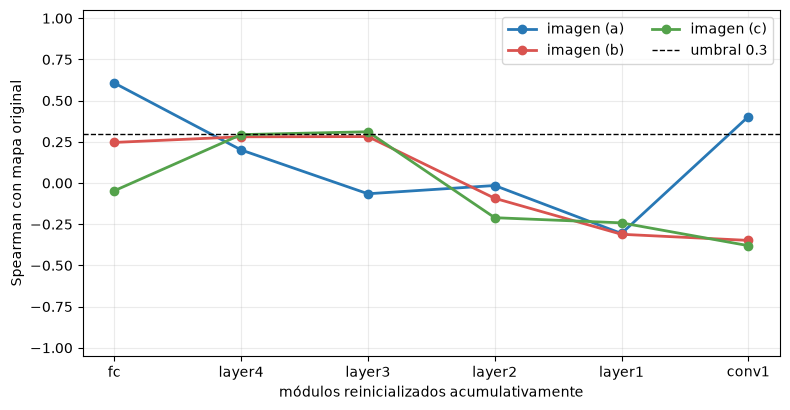

In [18]:
def normalized_relu7(tensor):
    values = tensor.detach().float().cpu().numpy().reshape(7, 7)
    values = np.maximum(values, 0)
    return (values - values.min()) / (values.max() - values.min() + 1e-12)

def reset_parameters_in(module, seed):
    torch.manual_seed(seed)
    for submodule in module.modules():
        if hasattr(submodule, "reset_parameters"):
            submodule.reset_parameters()

randomized_model = copy.deepcopy(model).to(DEVICE).eval()
randomization_stages = [
    ("fc", randomized_model.fc),
    ("layer4", randomized_model.layer4),
    ("layer3", randomized_model.layer3),
    ("layer2", randomized_model.layer2),
    ("layer1", randomized_model.layer1),
    ("conv1", randomized_model.conv1),
]
original_maps7 = {key: normalized_relu7(gc[key]["relu7"][0, 0]) for key in "abc"}
randomization_rows = []
for stage_number, (stage_name, stage_module) in enumerate(randomization_stages, start=1):
    reset_parameters_in(stage_module, SEED + 4200 + stage_number)
    randomized_model.eval()
    random_gradcam = GradCAM(randomized_model, randomized_model.layer4)
    row = {"etapa": stage_name}
    for key in "abc":
        result = random_gradcam.compute(input_tensors[key], primary_class[key])
        new_map = normalized_relu7(result["relu7"][0, 0])
        rho = float(spearmanr(original_maps7[key].ravel(), new_map.ravel()).statistic)
        if not np.isfinite(rho):
            rho = 0.0
        row[key] = rho
    random_gradcam.close()
    randomization_rows.append(row)

randomization_table = pd.DataFrame(randomization_rows)
print(randomization_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.2))
for key, color_line in zip("abc", ["#2878B5", "#D9534F", "#54A24B"]):
    ax.plot(randomization_table["etapa"], randomization_table[key], marker="o",
            linewidth=2, label=f"imagen ({key})", color=color_line)
ax.axhline(0.3, color="black", linestyle="--", linewidth=1, label="umbral 0.3")
ax.set_ylabel("Spearman con mapa original")
ax.set_xlabel("módulos reinicializados acumulativamente")
ax.set_ylim(-1.05, 1.05)
ax.grid(alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "task4_aleatorizacion.png", dpi=180, bbox_inches="tight")
plt.show()

RESULTS["task4_2"] = randomization_rows

### Task 4.3 - Confiabilidad y audiencias

In [19]:
# (a) Comparación de la referencia gris con una referencia desenfocada para imagen (a).
curves_a = task4_curves["a"]
blur_deletion_a = perturbation_curve(
    display_tensors["a"].cpu(), curves_a["important_order"], primary_class["a"],
    "deletion", curves_a["blur_reference"]
)
auc_blur_deletion_a = float(blur_deletion_a.mean())
auc_gray_deletion_a = float(metric_table.loc[metric_table["imagen"] == "a", "AUC_del_mapa"].iloc[0])

# (b) Primera etapa acumulativa donde la correlación cae por debajo de 0.3.
first_below = {}
for key in "abc":
    below = randomization_table.loc[randomization_table[key] < 0.3, "etapa"].tolist()
    first_below[key] = below[0] if below else "ninguna"

print("Desempeño contra el azar, en desviaciones estándar")
for row in metric_rows:
    print(f"Imagen ({row['imagen']}): z_deletion={row['z_del']:+.2f}, "
          f"z_insertion={row['z_ins']:+.2f}")
print(f"Imagen (a), AUC deletion con gris={auc_gray_deletion_a:.4f}, "
      f"con desenfoque={auc_blur_deletion_a:.4f}")
print("Primera etapa con Spearman < 0.3:", first_below)

RESULTS["task4_3"] = {
    "auc_deletion_gris_a": auc_gray_deletion_a,
    "auc_deletion_desenfoque_a": auc_blur_deletion_a,
    "primera_etapa_spearman_menor_03": first_below,
    "audiencias": {
        "solicitante": "razones principales y contrafactuales accionables con advertencias",
        "cumplimiento": "SHAP global y local, LIME con fidelidad y pruebas de estabilidad",
        "regulador": "metodología, datos, supuestos, validaciones y trazabilidad completa",
    },
}

Desempeño contra el azar, en desviaciones estándar
Imagen (a): z_deletion=+4.77, z_insertion=+23.78
Imagen (b): z_deletion=-18.41, z_insertion=+39.03
Imagen (c): z_deletion=+1.25, z_insertion=+102.26
Imagen (a), AUC deletion con gris=0.0471, con desenfoque=0.0917
Primera etapa con Spearman < 0.3: {'a': 'layer4', 'b': 'fc', 'c': 'fc'}


**Interpretación del Task 4.3.**

**(a)** Los puntajes $z$ anteriores expresan cuántas desviaciones estándar separan al mapa de los diez órdenes aleatorios. Las curvas tienen escalones y mesetas porque el mapa procede de solo $7\times7$ posiciones y la interpolación asigna regiones amplias a valores muy parecidos. La comparación gris frente a desenfoque en la imagen (a) cuantifica cuánto depende *deletion* del artefacto introducido por la referencia.

**(b)** Al aleatorizar solo *fc*, las activaciones de *layer4* permanecen iguales pero cambian los pesos de clase. Como $\alpha_k^c=w_k^c/Z$, el mapa debería perder correlación de inmediato; la primera fila de la tabla contrasta directamente esa predicción. Las etapas posteriores prueban si cualquier similitud residual depende de rasgos cada vez más tempranos.

**(c)** Para la persona solicitante se entregarían razones locales en lenguaje claro y, solo en un contexto de crédito, cambios accionables factibles, sin exponer log-odds ni detalles innecesarios del modelo. Al oficial de cumplimiento se entregarían SHAP local y global, fidelidad y estabilidad de LIME, restricciones de los contrafactuales y evidencia de eficiencia. Al regulador se entregarían además procedencia de datos, codificación, semillas, supuestos de dependencia, pruebas numéricas y trazabilidad reproducible. No se presentaría ninguna técnica como causal.

En detección de lavado, un contrafactual que revele cambios exactos para cruzar el umbral facilitaría evasión y manipulación. En su lugar se entregarían categorías generales de señales, justificación para revisión humana, evidencia agregada, controles de auditoría y un canal de apelación, sin publicar umbrales ni combinaciones accionables.

In [20]:
def json_ready(obj):
    if isinstance(obj, dict):
        return {str(k): json_ready(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [json_ready(v) for v in obj]
    if isinstance(obj, (np.floating, np.integer)):
        return obj.item()
    return obj

with open(ROOT / "output" / "resultados.json", "w", encoding="utf-8") as f:
    json.dump(json_ready(RESULTS), f, ensure_ascii=False, indent=2)
gradcam.close()
print("Resultados guardados en output/resultados.json")

Resultados guardados en output/resultados.json
